## 1. Introduction

Tái lập **baseline NPR gốc** trên toàn bộ ảnh test local hợp lệ của ProGAN, StyleGAN2 và sdv1. Không train/fine-tune, không đổi kiến trúc, không tải dữ liệu. Real=0, Fake=1. Kết quả local không tự động tương đương benchmark paper. Các cell dùng chung inference.py, evaluation.py và reporting.py. Mặc định đọc kết quả đã chạy; bật các cờ dưới đây để chạy lại bước dài.

In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd()
if not (ROOT / 'inference.py').is_file():
    ROOT = ROOT / 'NPR-DeepfakeDetection'
assert (ROOT / 'inference.py').is_file(), 'Mở notebook từ thư mục dự án hoặc D:/XLA'
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
RERUN_AUDIT = False
RERUN_EVALUATION = False
RERUN_REPORTS = False
RESULTS = ROOT / 'results'
print('Project:', ROOT)


Project: D:\XLA\NPR-DeepfakeDetection


## 2. Environment Check

CPU là cấu hình đã thực nghiệm. Không gọi CUDA. Danh sách phiên bản thực tế và seed được ghi trong experiment_config.json. Notebook không tự pip install.

In [2]:
import torch, torchvision, numpy as np, pandas as pd
from IPython.display import display, Image as DisplayImage, Markdown
from inference import load_model, read_rgb, PREPROCESS_CONFIG
from evaluation import audit, evaluate, fingerprint
print(sys.version)
print('torch:', torch.__version__, '| torchvision:', torchvision.__version__)
print('CUDA available:', torch.cuda.is_available(), '| evaluation device: CPU')


3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
torch: 2.15.0+cpu | torchvision: 0.29.2+cpu
CUDA available: False | evaluation device: CPU


D:\XLA\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Dataset Audit

Quét đệ quy và chỉ gán nhãn từ thư mục có tên xác định. Ảnh hỏng, nhãn không rõ hoặc hash có nhãn xung đột bị loại khỏi đánh giá. Không xóa dữ liệu gốc; giữ các đường dẫn trùng cùng nhãn và báo cáo riêng. Metadata nguồn chưa được xác minh. Valid nghĩa là verify/decode được. Ảnh đơn sắc được gắn cờ trong image_quality_flags.csv để kiểm tra thủ công; vẫn giữ trong baseline chính, không coi số bản sao là các tình huống thị giác độc lập.

In [3]:
if RERUN_AUDIT:
    manifest = audit()
else:
    manifest = pd.read_csv(RESULTS / 'data_manifest.csv')
data_audit = pd.read_csv(RESULTS / 'data_audit.csv')
display(data_audit[['Dataset','Real','Fake','Total','Valid','Invalid','Unknown','Eligible','DuplicateFiles','CrossDatasetDuplicateFiles']])
display(Markdown((RESULTS / 'data_audit.md').read_text(encoding='utf-8')))


,Dataset,Real,Fake,Total,Valid,Invalid,Unknown,Eligible,DuplicateFiles,CrossDatasetDuplicateFiles
0,progan,4000,4000,8000,8000,0,0,8000,400,400
1,stylegan2,7988,7988,15976,15976,0,0,15976,404,400
2,sdv1,5000,10000,15000,15000,0,0,15000,105,0


# Kiểm tra dữ liệu thực tế

| Dataset | Path | Real | Fake | Total | Valid | Invalid | Unknown | Eligible | Formats | DuplicateFiles | CrossDatasetDuplicateFiles | Provenance |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| progan | D:\XLA\NPR-DeepfakeDetection\datasets\progan | 4000 | 4000 | 8000 | 8000 | 0 | 0 | 8000 | {"PNG": 8000} | 400 | 400 | Not Verified |
| stylegan2 | D:\XLA\NPR-DeepfakeDetection\datasets\stylegan2 | 7988 | 7988 | 15976 | 15976 | 0 | 0 | 15976 | {"PNG": 15976} | 404 | 400 | Not Verified |
| sdv1 | D:\XLA\NPR-DeepfakeDetection\datasets\sdv1 | 5000 | 10000 | 15000 | 15000 | 0 | 0 | 15000 | {"PNG": 10000, "JPEG": 5000} | 105 | 0 | Not Verified |

## Kích thước ảnh

| Dataset | Distinct_sizes | Width_range | Height_range | Top_dimensions |
| --- | --- | --- | --- | --- |
| progan | 1 | 256–256 | 256–256 | 256×256: 8000 |
| stylegan2 | 2 | 256–512 | 256–384 | 256×256: 11982; 512×384: 3994 |
| sdv1 | 964 | 77–3888 | 60–5005 | 512×512: 10000; 500×375: 1577; 375×500: 463; 500×333: 302; 500×500: 174; 333×500: 97; 500×334: 87; 500×400: 70 |

Phân bố kích thước đầy đủ trong data_audit.csv (Dimensions), từng ảnh trong data_manifest.csv.

Nhãn chỉ lấy từ thành phần thư mục chính xác: 0_real/real = 0, 1_fake/fake = 1. Ảnh không rõ nhãn hoặc có nhãn xung đột không được đánh giá. Không thay đổi dữ liệu gốc. File lỗi: invalid_images.csv; cần kiểm tra nhãn: manual_review.csv; trùng byte: exact_duplicates.csv. Giữ toàn bộ đường dẫn test hợp lệ, kể cả bản trùng cùng nhãn; không gộp chỉ số giữa các nguồn. SHA256 phát hiện trùng byte, không phát hiện ảnh giống nhau sau nén/chỉnh sửa, không chứng minh không có train/test leakage.

## Nguồn dữ liệu

Không có metadata nguồn trong ba thư mục ảnh hiện tại. Tên thư mục và nội dung ảnh không đủ chứng minh generator, checkpoint sinh ảnh hoặc split. ProGAN/StyleGAN2 có cấu trúc tương thích ForenSynths nhưng chưa xác minh danh sách ảnh benchmark. sdv1 có nhãn thư mục và được đánh giá như nguồn local sdv1; không xác nhận thực sự được sinh bởi Stable Diffusion v1. Không coi sdv1 tương đương sdv1_new. DIRE có dữ liệu ảnh RGB, ảnh tái dựng và residual DIRE; NPR nhận ảnh RGB, tự tính NPR, không nhận residual DIRE. Không có metadata để chứng minh các file local là gói RGB gốc nào. README tác giả tổ chức lại benchmark dưới DiffusionForensics/sdv1_new; đổi tên thư mục không chứng minh tương đương.

datasets/test được kiểm tra riêng, không tự động trộn vào ba nguồn: 0 file.

Thời gian audit: 108.37 giây.


## Chi tiết trùng lặp

| Dataset | WithinDatasetDuplicateFiles | WithinDatasetDuplicateGroups | WithinDatasetExtraCopies | CrossDatasetDuplicateFiles |
| --- | --- | --- | --- | --- |
| progan | 0 | 0 | 0 | 400 |
| stylegan2 | 4 | 2 | 2 | 400 |
| sdv1 | 105 | 2 | 103 | 0 |

DuplicateFiles trong bảng audit chính tính các file có bản trùng ở bất kỳ nguồn nào. Bảng này tách trùng nội bộ và trùng giữa nguồn; ExtraCopies đếm số bản dư ngoài một bản cho mỗi hash. Các nguồn có ảnh trùng không độc lập hoàn toàn.

Đã kiểm tra header/EXIF của 38976 ảnh; có 0 metadata ứng viên liên quan generator/prompt/checkpoint. Chi tiết ở provenance_header_audit.json. Không có metadata xác minh generator trong lượt này; tên file sdv1 gồm hậu tố real/ILSVRC và fake không đủ xác minh nguồn sinh ảnh.


### Cờ chất lượng nội dung

| dataset | flag | true_label | files | unique_hashes | errors |
| --- | --- | --- | --- | --- | --- |
| sdv1 | all_black | 1 | 103 | 1 | 103 |

Valid/Invalid trong bảng audit là khả năng verify/decode ảnh. Ảnh đơn sắc đọc được vẫn thuộc baseline chính nhưng cần kiểm tra thủ công về chất lượng nội dung; xem image_quality_audit.md và image_quality_flags.csv. Không sửa, đổi nhãn hoặc xóa các ảnh này.


## 4. Load NPR Model

Dùng custom networks.resnet.resnet50(num_classes=1), không dùng ResNet50 của torchvision. NPR.pth có khóa model; module cũng hỗ trợ state dict phẳng như model_epoch_last_3090.pth, bỏ đúng tiền tố module. và strict=True. Baseline vẫn dùng NPR.pth; model_version gắn với SHA256 checkpoint. Bộ nhớ cache tái dùng từng phiên bản. Checkpoint trùng Git blob của repository local; xem source_audit.md.

In [4]:
detector = load_model()
model = detector.model
print(detector.load_result)
print('Parameters:', detector.parameter_count, '| State entries:', detector.state_entries)
print('Checkpoint SHA256:', detector.checkpoint_sha256)
assert not model.training
config = json.loads((ROOT / 'experiment_config.json').read_text(encoding='utf-8'))
if not RERUN_EVALUATION:
    assert fingerprint(manifest, detector.checkpoint_sha256) == config['run_fingerprint'], 'Cache không khớp; chạy evaluation.py'


<All keys matched successfully>
Parameters: 1437761 | State entries: 146
Checkpoint SHA256: 3939297e9399e0b992f87211610769d87d899de50d56da0204d6cbda2d483a53


## 5. Image Preprocessing

Theo test.py cho ForenSynths/DiffusionForensics: RGB → Resize((256,256), bilinear) → ToTensor → Normalize ImageNet. Không crop, flip, augmentation hay EXIF transpose. data/datasets.py đặt LOAD_TRUNCATED_IMAGES=True; pipeline này kiểm tra decode nghiêm ngặt để loại file lỗi theo yêu cầu. Không tính NPR ở bước preprocessing.

{
  "resize": [
    256,
    256
  ],
  "interpolation": "bilinear",
  "crop": false,
  "flip": false,
  "rgb": true,
  "exif_transpose": false,
  "mean": [
    0.485,
    0.456,
    0.406
  ],
  "std": [
    0.229,
    0.224,
    0.225
  ]
}
Ảnh: datasets/progan/airplane/0_real/00049.png | Original size: (256, 256) | Tensor: (1, 3, 256, 256)


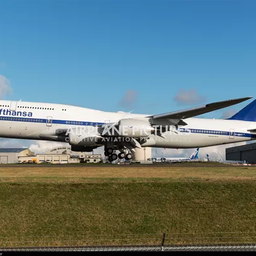

In [5]:
print(json.dumps(PREPROCESS_CONFIG, indent=2))
sample = manifest[manifest.eligible].iloc[0]
sample_path = ROOT / sample.image_path
image = read_rgb(sample_path)
x = detector.preprocess(image).unsqueeze(0)
print('Ảnh:', sample.image_path, '| Original size:', image.size, '| Tensor:', tuple(x.shape))
display(image.resize((256,256)))


## 6. NPR Visualization

Trong forward, NPR = x − up_nearest(down_nearest(x,0.5),2), rồi nhân 2/3 trước convolution. NPR biểu diễn chênh lệch so với pixel tham chiếu trong ô 2×2. Hình dưới chỉ minh họa; không đưa residual trở lại mạng để tránh tính NPR hai lần.

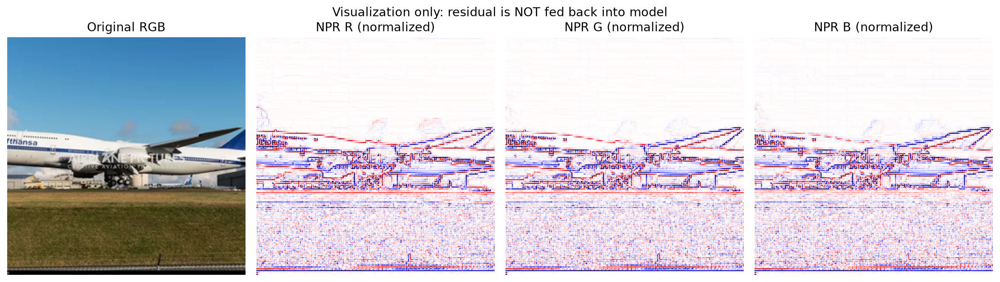

In [6]:
from reporting import model_visuals
if RERUN_REPORTS or not (RESULTS/'figures/npr_visualization.png').exists():
    model_visuals(detector, manifest)
display(DisplayImage(filename=str(RESULTS/'figures/npr_visualization.png')))


## 7. CNN Architecture

Mạng nhẹ 1.437.761 tham số: Conv3×3 stride2 → BN/ReLU/MaxPool → layer1 với 3 Bottleneck → layer2 với 4 Bottleneck → AdaptiveAvgPool → Linear(512,1). Tên resnet50 không có nghĩa là mạng ResNet50 đầy đủ.

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

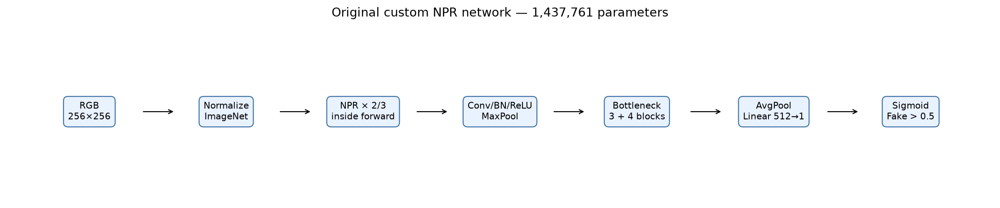

In [7]:
print(model)
display(DisplayImage(filename=str(RESULTS/'figures/npr_architecture.png')))


## 8. Single Image Inference

Raw logit đi qua sigmoid thành fake_score. Chỉ khi score > 0.5 mới dự đoán Fake, đúng validate.py tác giả. Score là điểm mô hình, chưa được hiệu chuẩn thành xác suất thực tế.

In [8]:
single_result = detector.predict(sample_path)
display(pd.DataFrame([single_result]))
assert 0 <= single_result['fake_score'] <= 1
json.dumps(single_result)


,label,raw_logit,fake_score,inference_time_ms,model_version,checkpoint_sha256
0,REAL,-43.209312,1.715671e-19,88.6008,npr-sha256:3939297e9399e0b992f87211610769d87d8...,3939297e9399e0b992f87211610769d87d899de50d56da...


'{"label": "REAL", "raw_logit": -43.209312438964844, "fake_score": 1.7156712058736322e-19, "inference_time_ms": 88.60079999431036, "model_version": "npr-sha256:3939297e9399e0b992f87211610769d87d899de50d56da0204d6cbda2d483a53", "checkpoint_sha256": "3939297e9399e0b992f87211610769d87d899de50d56da0204d6cbda2d483a53"}'

## 9. Multi-Image Inference

Dùng cùng detector, không load lại checkpoint. Batch có chung resize 256×256; thời gian mỗi ảnh là thời gian batch (decode/preprocess/forward/sigmoid) chia cho số ảnh, không phải phép đo latency ảnh đơn độc lập.

In [9]:
examples = manifest[manifest.eligible].groupby('true_label',sort=True).head(2)
outputs = detector.predict_batch([ROOT/p for p in examples.image_path])
display(pd.concat([examples[['dataset','image_path','true_label']].reset_index(drop=True),pd.DataFrame(outputs)],axis=1))


,dataset,image_path,true_label,label,raw_logit,fake_score,inference_time_ms,model_version,checkpoint_sha256
0,progan,datasets/progan/airplane/0_real/00049.png,0,REAL,-43.209312,1.715671e-19,34.764175,npr-sha256:3939297e9399e0b992f87211610769d87d8...,3939297e9399e0b992f87211610769d87d899de50d56da...
1,progan,datasets/progan/airplane/0_real/00069.png,0,REAL,-54.509922,2.121493e-24,34.764175,npr-sha256:3939297e9399e0b992f87211610769d87d8...,3939297e9399e0b992f87211610769d87d899de50d56da...
2,progan,datasets/progan/airplane/1_fake/00049.png,1,FAKE,107.869949,1.000000e+00,34.764175,npr-sha256:3939297e9399e0b992f87211610769d87d8...,3939297e9399e0b992f87211610769d87d899de50d56da...
3,progan,datasets/progan/airplane/1_fake/00069.png,1,FAKE,79.590668,1.000000e+00,34.764175,npr-sha256:3939297e9399e0b992f87211610769d87d8...,3939297e9399e0b992f87211610769d87d899de50d56da...


## 10. ProGAN Evaluation

Mặc định đọc kết quả đã lưu từ inference thật, đã bổ sung image_id/model_version mà giữ nguyên số đo gốc. Xem handover_upgrade_verification.json để kiểm chứng nâng cấp metadata. Nếu bật RERUN_EVALUATION, đánh giá chung cả ba nguồn và tiếp tục từ các batch đã lưu có fingerprint khớp. Không giới hạn 1.000 ảnh. AP lấy fake_score liên tục, positive=Fake.

In [10]:
if RERUN_EVALUATION:
    predictions, metrics = evaluate(manifest, detector)
else:
    predictions = pd.read_csv(RESULTS/'per_image_predictions.csv')
    metrics = pd.read_csv(RESULTS/'baseline_metrics.csv')
display(metrics[metrics.Dataset=='progan'])


,Dataset,Real,Fake,Total,Accuracy,Precision,Recall,F1,AP,ROC_AUC,TN,FP,FN,TP,Time,MeanTime_ms,Eligible,Complete,Metric_note
0,progan,4000,4000,8000,0.997875,0.998249,0.9975,0.997874,0.999916,0.999902,3993,7,10,3990,344.315824,43.039478,8000,True,Fake=1 positive


## 11. StyleGAN2 Evaluation

Đánh giá toàn bộ đường dẫn hợp lệ hiện có; không bổ sung ảnh thiếu để ép bằng số lượng benchmark. Đây là nguồn khác ProGAN, nhưng chưa đủ metadata để xác nhận split chuẩn.

In [11]:
display(metrics[metrics.Dataset=='stylegan2'])

,Dataset,Real,Fake,Total,Accuracy,Precision,Recall,F1,AP,ROC_AUC,TN,FP,FN,TP,Time,MeanTime_ms,Eligible,Complete,Metric_note
1,stylegan2,7988,7988,15976,0.983913,0.997298,0.970456,0.983694,0.999364,0.999409,7967,21,236,7752,708.800316,44.36657,15976,True,Fake=1 positive


## 12. Stable Diffusion Evaluation

Tên sdv1 là tên nguồn local, chưa chứng minh generator Stable Diffusion v1 hay sự tương đương sdv1_new. Tỷ lệ Real/Fake mất cân bằng được giữ nguyên để đánh giá toàn bộ dữ liệu hiện có. Không dùng residual DIRE làm thay thế ảnh RGB.

In [12]:
display(metrics[metrics.Dataset=='sdv1'])

,Dataset,Real,Fake,Total,Accuracy,Precision,Recall,F1,AP,ROC_AUC,TN,FP,FN,TP,Time,MeanTime_ms,Eligible,Complete,Metric_note
2,sdv1,5000,10000,15000,0.968933,0.99114,0.962,0.976352,0.99582,0.995035,4914,86,380,9620,715.573088,47.704873,15000,True,Fake=1 positive


## 13. Confusion Matrix

Hàng là nhãn thật, cột là nhãn dự đoán; thứ tự Real rồi Fake. FP = Real bị coi là Fake, FN = Fake bị bỏ sót. Đọc số đếm tuyệt đối cùng tỷ lệ lớp.

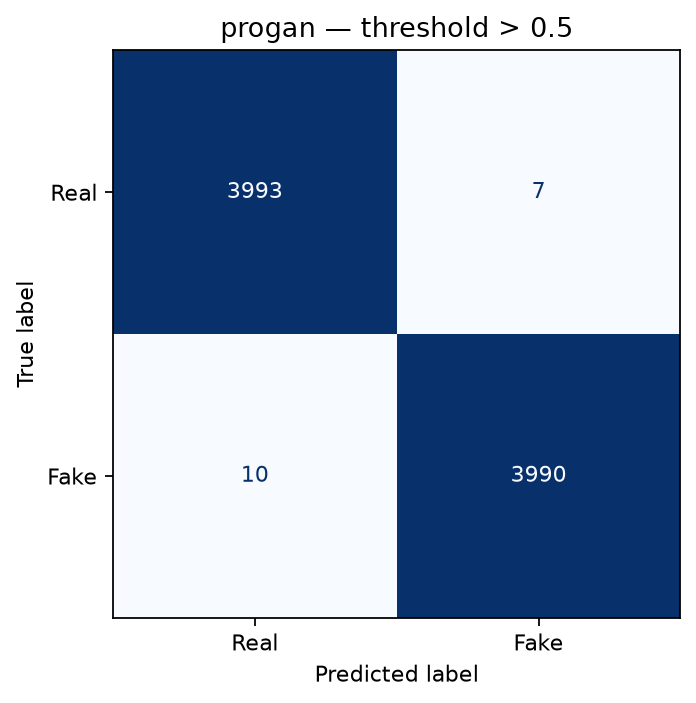

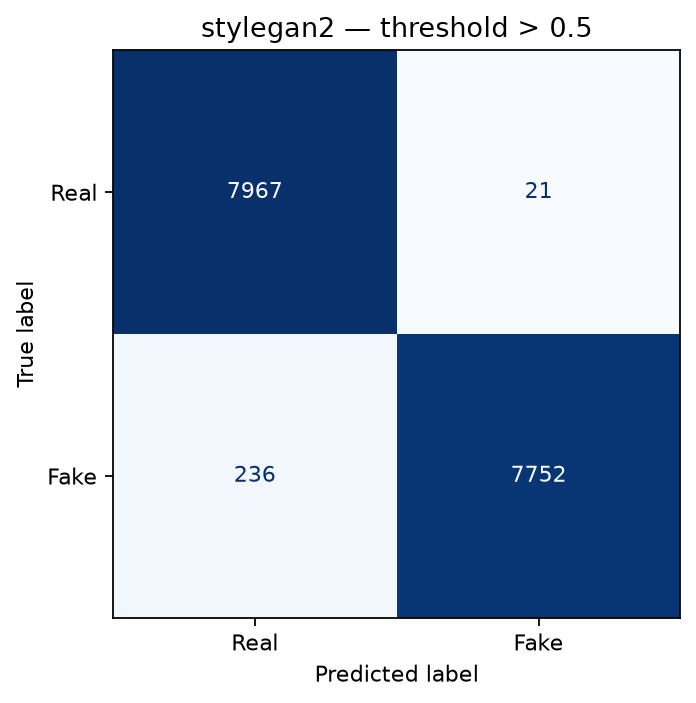

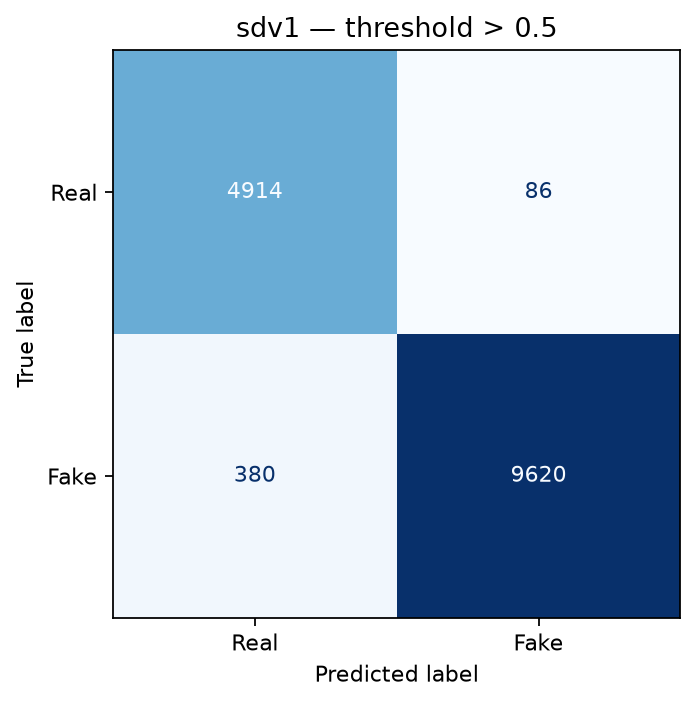

In [13]:
from reporting import generate_reports
if RERUN_REPORTS: generate_reports(detector)
for name in ['progan','stylegan2','sdv1']:
    display(DisplayImage(filename=str(RESULTS/f'figures/{name}_confusion_matrix.png')))


## 14. ROC / PR Curves

ROC-AUC và AP dùng score liên tục, không dùng nhãn threshold. PR thể hiện trade-off precision/recall; AP khác Accuracy và phụ thuộc tỷ lệ positive. Nếu chỉ có một lớp, không báo cáo AP/AUC như hợp lệ.

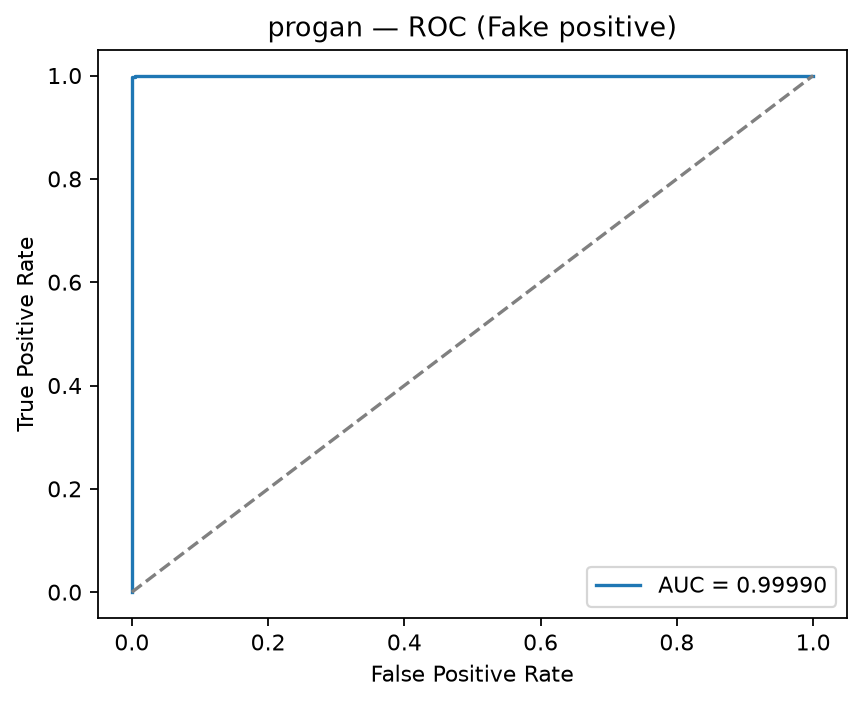

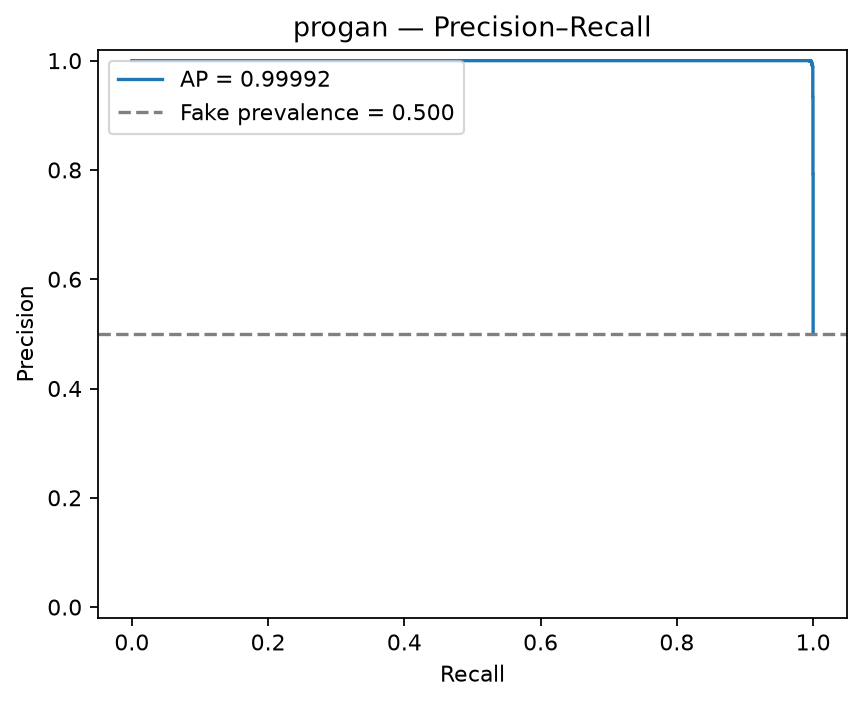

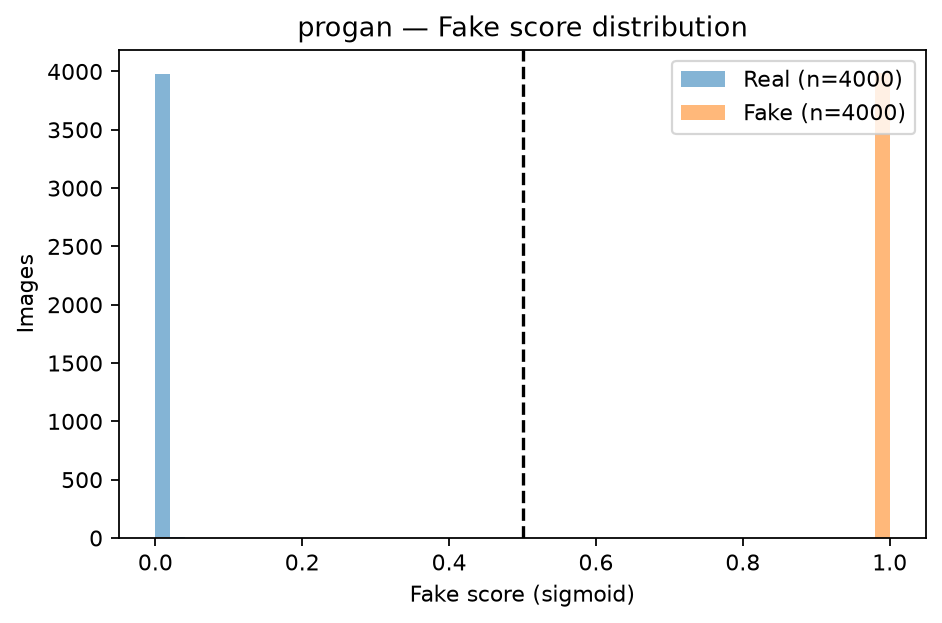

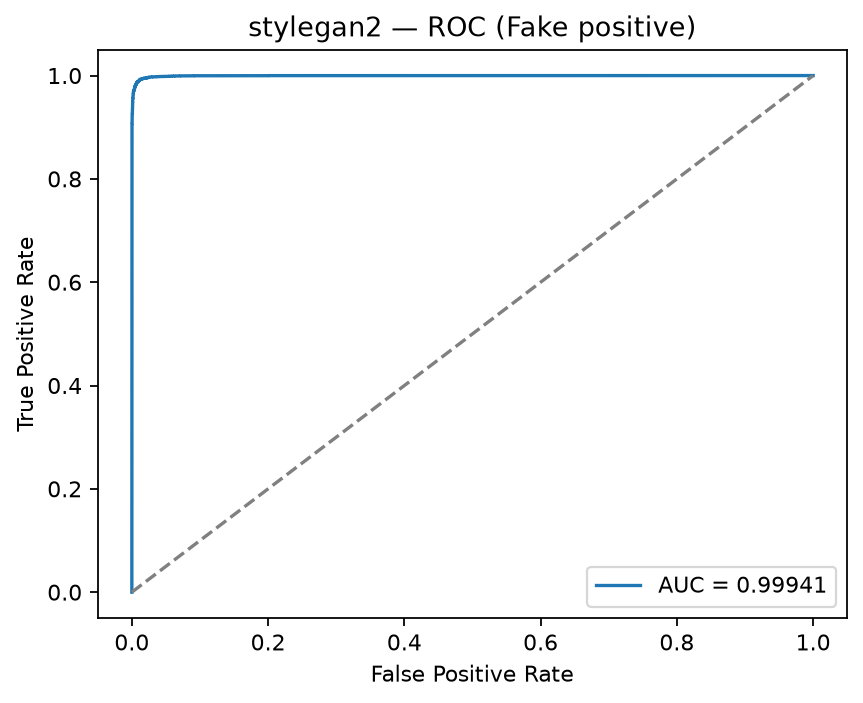

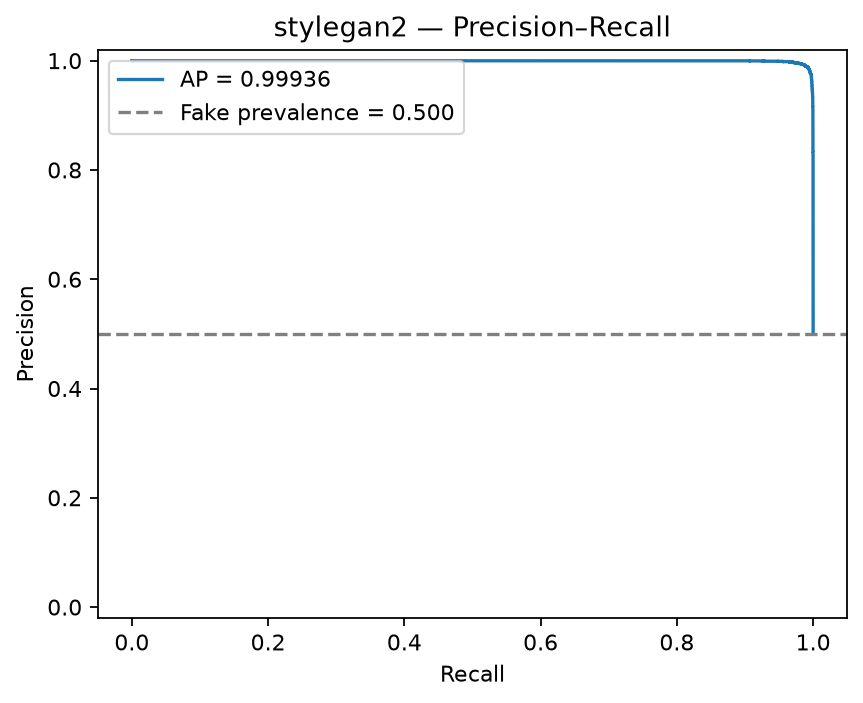

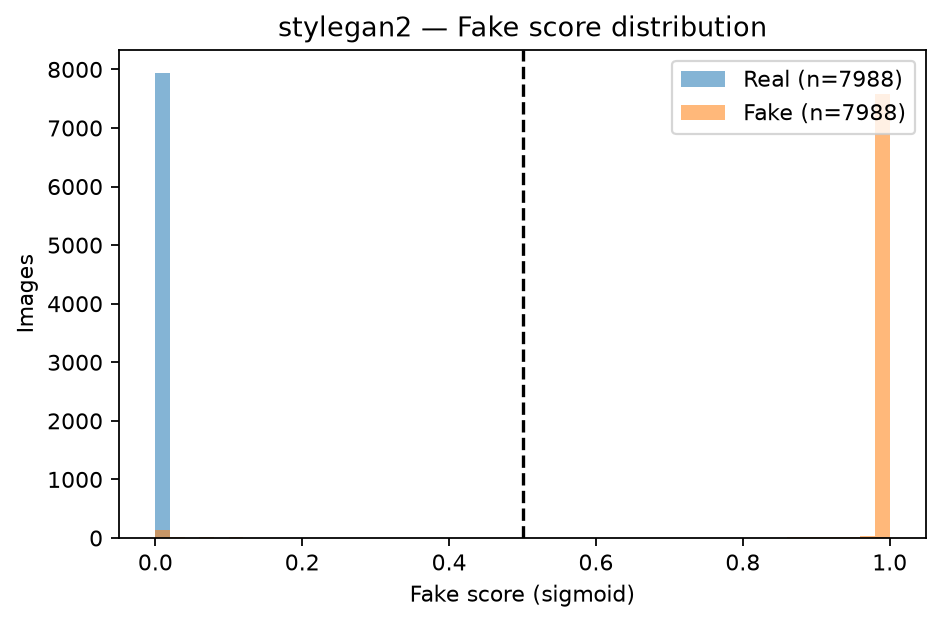

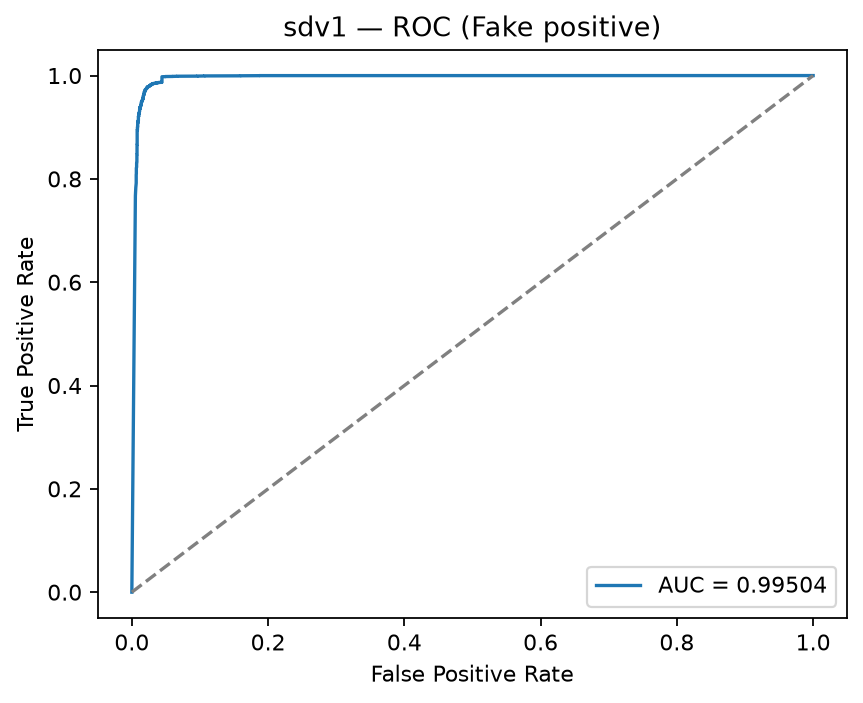

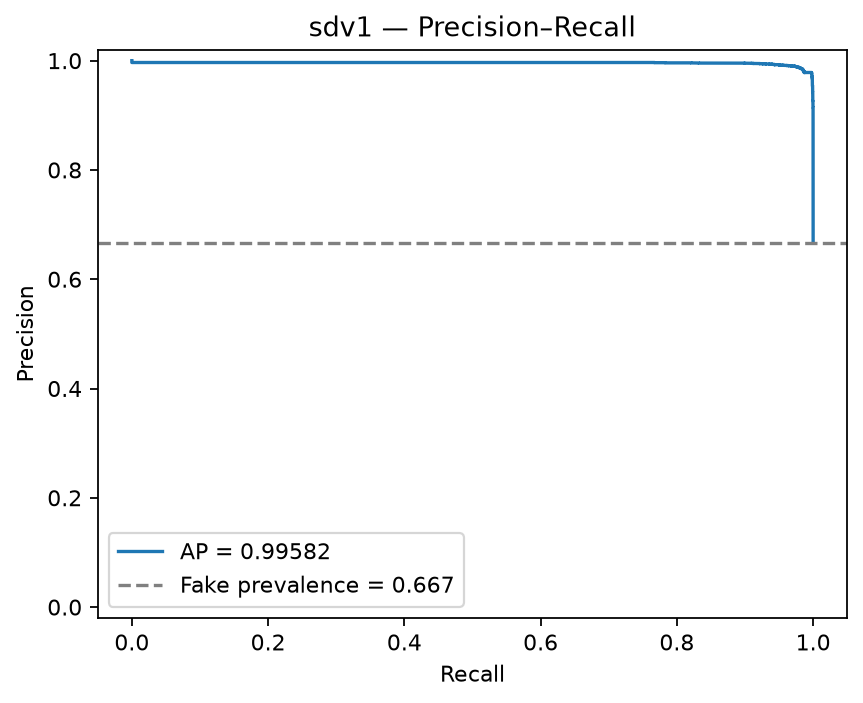

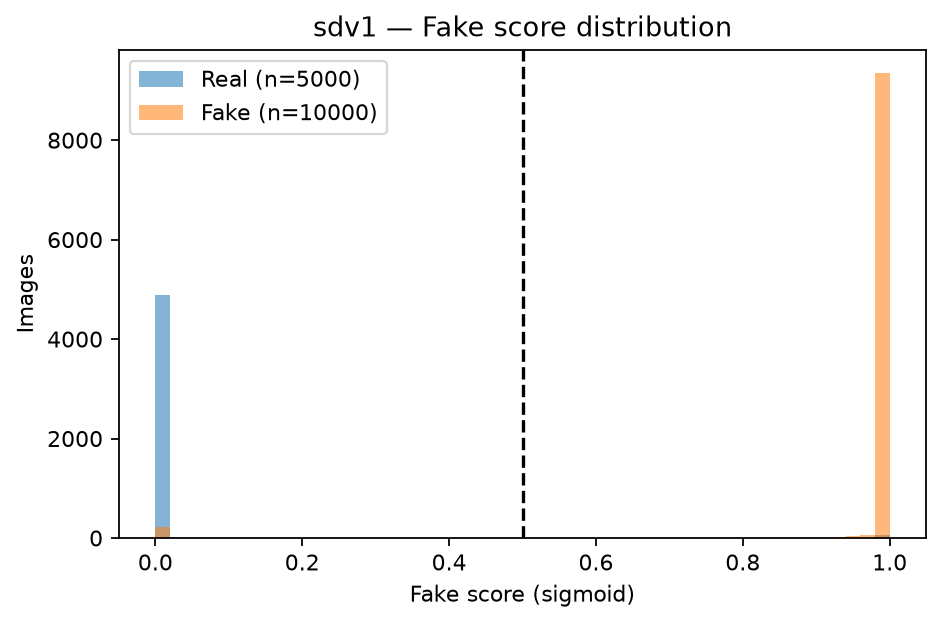

In [14]:
for name in ['progan','stylegan2','sdv1']:
    for kind in ['roc_curve','pr_curve','fake_score_distribution']:
        path=RESULTS/f'figures/{name}_{kind}.png'
        if path.exists(): display(DisplayImage(filename=str(path)))
        else: print(name,kind,': không đủ điều kiện, xem báo cáo')


## 15. Paper Comparison

Các số paper được kiểm tra từ bản tác giả arXiv v2, Tables 1/3. Chưa truy cập được PDF CVPR cuối cùng. Comparable=No do chưa xác minh archive/test split, và riêng sdv1 chưa xác minh sdv1_new. Chênh lệch điểm phần trăm chỉ mô tả, không chứng minh tái lập paper.

In [15]:
display(pd.read_csv(RESULTS/'paper_comparison.csv'))
display(Markdown((RESULTS/'paper_comparison.md').read_text(encoding='utf-8')))


,Dataset,Paper_Accuracy,Our_Accuracy,Paper_AP,Our_AP,Accuracy_Difference_pp,AP_Difference_pp,Comparable,Reason,Paper_Table,Source,Paper_version,CVPR_final_verification,Full_local_evaluation
0,progan,99.8,99.787500,100.0,99.991631,-0.012500,-0.008369,No,Local source archive and exact test split not ...,Table 1,https://arxiv.org/pdf/2312.10461v2,arXiv v2 (2023-12-20); CVPR final PDF not retr...,Not Verified,True
1,stylegan2,97.3,98.391337,100.0,99.936418,1.091337,-0.063582,No,Local source archive and exact test split not ...,Table 1,https://arxiv.org/pdf/2312.10461v2,arXiv v2 (2023-12-20); CVPR final PDF not retr...,Not Verified,True
2,sdv1,97.4,96.893333,99.8,99.581963,-0.506667,-0.218037,No,Local source archive and exact test split not ...,Table 3,https://arxiv.org/pdf/2312.10461v2,arXiv v2 (2023-12-20); CVPR final PDF not retr...,Not Verified,True


# Đối chiếu paper NPR

| Dataset | Paper_Accuracy | Our_Accuracy | Paper_AP | Our_AP | Accuracy_Difference_pp | AP_Difference_pp | Comparable |
| --- | --- | --- | --- | --- | --- | --- | --- |
| progan | 99.8 | 99.7875 | 100.0 | 99.99163052795261 | -0.012500000000002842 | -0.008369472047391469 | No |
| stylegan2 | 97.3 | 98.39133700550826 | 100.0 | 99.93641769193573 | 1.0913370055082652 | -0.06358230806426945 | No |
| sdv1 | 97.4 | 96.89333333333333 | 99.8 | 99.58196328519983 | -0.5066666666666748 | -0.21803671480016362 | No |

Đơn vị: phần trăm; chênh lệch là điểm phần trăm, không phải phần trăm tương đối. Đây là chênh lệch mô tả, không phải bằng chứng tái lập benchmark.

Nguồn số liệu đã đọc: [bản tác giả arXiv v2, trang 6, Tables 1 và 3](https://arxiv.org/pdf/2312.10461v2). Table 1: NPR ProGAN Acc/AP 99.8/100.0; StyleGAN2 97.3/100.0. Table 3: NPR Stable Diffusion v1 97.4/99.8. PDF CVPR cuối cùng không truy cập được qua công cụ trong phiên; không tuyên bố đã xác minh bản CVPR cuối cùng.

Checkpoint NPR.pth được xác nhận trùng Git blob của repository local; không đổi sang model_epoch_last_3090.pth. Tiền xử lý khớp test.py local cho ForenSynths/DiffusionForensics. Chưa có manifest chính thức để so sánh toàn bộ test split/ảnh và chưa xác minh nguồn archive local; mọi hàng Comparable=No. Chạy toàn bộ ảnh local không đồng nghĩa đã chạy toàn bộ benchmark paper.

NPR README chỉ rõ sdv1_new trong DiffusionForensics. DIRE gốc tổ chức images/recons/dire theo split và domain; NPR sắp xếp theo generator/nhãn. Các tên này không chứng minh hai tập local tương đương. Tham khảo [NPR repository](https://github.com/chuangchuangtan/NPR-DeepfakeDetection) và [DIRE dataset layout](https://github.com/ZhendongWang6/DIRE#diffusionforensics-dataset).

**progan:** Local source archive and exact test split not verified; original NPR.pth matches repository, protocol matches local author source; environment differs.

**stylegan2:** Local source archive and exact test split not verified; original NPR.pth matches repository, protocol matches local author source; environment differs.

**sdv1:** Local source archive and exact test split not verified; original NPR.pth matches repository, protocol matches local author source; environment differs. Generator identity and sdv1_new equivalence unverified; local ImageNet-only source is imbalanced (1:2).

## 16. Error Analysis

Xem mẫu đúng, sai tự tin cao và gần threshold 0.5. Chỉ kết luận theo số đo thực tế, không suy diễn nguyên nhân thị giác khi chưa kiểm chứng. Danh sách đầy đủ có trong error_analysis.csv.

# Phân tích lỗi trên dữ liệu thực tế

| Dataset | Real | Fake | Total | Accuracy | Precision | Recall | F1 | AP | ROC_AUC | TN | FP | FN | TP | Time | MeanTime_ms | Eligible | Complete | Metric_note |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| progan | 4000 | 4000 | 8000 | 0.997875 | 0.9982486865148862 | 0.9975 | 0.9978742028260598 | 0.999916305279526 | 0.9999015000000001 | 3993 | 7 | 10 | 3990 | 344.3158235998271 | 43.03947794997839 | 8000 | True | Fake=1 positive |
| stylegan2 | 7988 | 7988 | 15976 | 0.9839133700550826 | 0.9972983404091085 | 0.9704556835252879 | 0.9836939280502506 | 0.9993641769193573 | 0.9994090252805348 | 7967 | 21 | 236 | 7752 | 708.800316199995 | 44.36656961692508 | 15976 | True | Fake=1 positive |
| sdv1 | 5000 | 10000 | 15000 | 0.9689333333333333 | 0.9911395013393777 | 0.962 | 0.9763523799857912 | 0.9958196328519984 | 0.99503507 | 4914 | 86 | 380 | 9620 | 715.5730882000715 | 47.70487254667144 | 15000 | True | Fake=1 positive |

Trong ba nguồn local, Accuracy cao nhất: progan (99.7875%); thấp nhất: sdv1 (96.8933%). Trung bình Accuracy hai nguồn GAN (không trọng số): 99.0894%; sdv1 local: 96.8933%; chênh lệch sdv1 − GAN: -2.1961 điểm %. Đây chỉ là quan sát trên các tập local khác nội dung và tỷ lệ lớp; không chứng minh tác động nhân quả của GAN/Diffusion, đặc biệt danh tính nguồn sdv1 chưa được xác minh.

- progan: FP=7, FN=10; Real=4000, Fake=4000; Recall Fake=99.7500%.
  Trong các lỗi của nguồn này, bỏ sót Fake (FN) chiếm 58.82%; cần xem false negatives khi nghiên cứu cải tiến.
- stylegan2: FP=21, FN=236; Real=7988, Fake=7988; Recall Fake=97.0456%.
  Trong các lỗi của nguồn này, bỏ sót Fake (FN) chiếm 91.83%; cần xem false negatives khi nghiên cứu cải tiến.
- sdv1: FP=86, FN=380; Real=5000, Fake=10000; Recall Fake=96.2000%.
  Trong các lỗi của nguồn này, bỏ sót Fake (FN) chiếm 81.55%; cần xem false negatives khi nghiên cứu cải tiến.

## Theo danh mục

| dataset | category | total | errors | accuracy |
| --- | --- | --- | --- | --- |
| progan | airplane | 400 | 1 | 0.9975 |
| progan | bicycle | 400 | 5 | 0.9875 |
| progan | bird | 400 | 1 | 0.9975 |
| progan | boat | 400 | 0 | 1.0 |
| progan | bottle | 400 | 0 | 1.0 |
| progan | bus | 400 | 0 | 1.0 |
| progan | car | 400 | 0 | 1.0 |
| progan | cat | 400 | 0 | 1.0 |
| progan | chair | 400 | 0 | 1.0 |
| progan | cow | 400 | 1 | 0.9975 |
| progan | diningtable | 400 | 1 | 0.9975 |
| progan | dog | 400 | 0 | 1.0 |
| progan | horse | 400 | 0 | 1.0 |
| progan | motorbike | 400 | 2 | 0.995 |
| progan | person | 400 | 1 | 0.9975 |
| progan | pottedplant | 400 | 0 | 1.0 |
| progan | sheep | 400 | 1 | 0.9975 |
| progan | sofa | 400 | 0 | 1.0 |
| progan | train | 400 | 4 | 0.99 |
| progan | tvmonitor | 400 | 0 | 1.0 |
| sdv1 | imagenet | 15000 | 466 | 0.9689333333333333 |
| stylegan2 | car | 3994 | 21 | 0.9947421131697546 |
| stylegan2 | cat | 3994 | 1 | 0.9997496244366549 |
| stylegan2 | church | 3994 | 42 | 0.9894842263395093 |
| stylegan2 | horse | 3994 | 193 | 0.9516775162744117 |

## Ảnh đơn sắc và lỗi lặp lại

| dataset | flag | true_label | files | unique_hashes | errors |
| --- | --- | --- | --- | --- | --- |
| sdv1 | all_black | 1 | 103 | 1 | 103 |

Các nhóm ảnh đơn sắc có thể lặp cùng một nội dung và gây nhiều lỗi đếm theo đường dẫn. Số lỗi trong bảng không đồng nghĩa có bấy nhiêu tình huống thị giác độc lập. Kết quả chính vẫn tính mọi đường dẫn decode hợp lệ; xem image_quality_audit.md và image_quality_flags.csv để kiểm tra thủ công. Không coi sai sót trên ảnh đen là bằng chứng riêng về điểm yếu trên ảnh diffusion chân thực.


## Quan sát đặc điểm các ảnh sai

- progan: 1/17 ảnh sai có độ lệch trung bình giữa kênh RGB < 1/255 sau resize (gần ảnh xám).
- sdv1: 103/466 ảnh sai có độ lệch trung bình giữa kênh RGB < 1/255 sau resize (gần ảnh xám).
- stylegan2: 0/257 ảnh sai có độ lệch trung bình giữa kênh RGB < 1/255 sau resize (gần ảnh xám).

Đây là thống kê trong nhóm dự đoán sai, chưa phải tỷ lệ lỗi của toàn bộ ảnh xám. Không suy ra ảnh xám gây lỗi khi chưa có nhóm đối chứng đầy đủ. Xem gallery và từng dòng CSV để kiểm tra trực tiếp.


## Gợi ý cho Người 2

Xem error_analysis.csv và gallery incorrect để kiểm tra các lỗi tự tin cao; near_threshold để xem mẫu không chắc chắn. Số lỗi theo danh mục ở trên là bằng chứng trực tiếp; không suy diễn đặc điểm thị giác gây lỗi chỉ từ tên file. Kiểm tra robustness với resize/JPEG hoặc phân tích từng domain là hướng nghiên cứu tiếp theo, chưa được đo ở baseline này. Không chọn threshold từ tập test để báo cáo cải tiến; dùng tập validation riêng và báo cáo cùng manifest test. Do tỷ lệ Fake của sdv1 là 2/3, AP cần diễn giải cùng prevalence; không gộp các nguồn rồi tuyên bố generalization. Kiểm tra duplicate/leakage và xác minh archive trước khi kết luận tái lập paper.


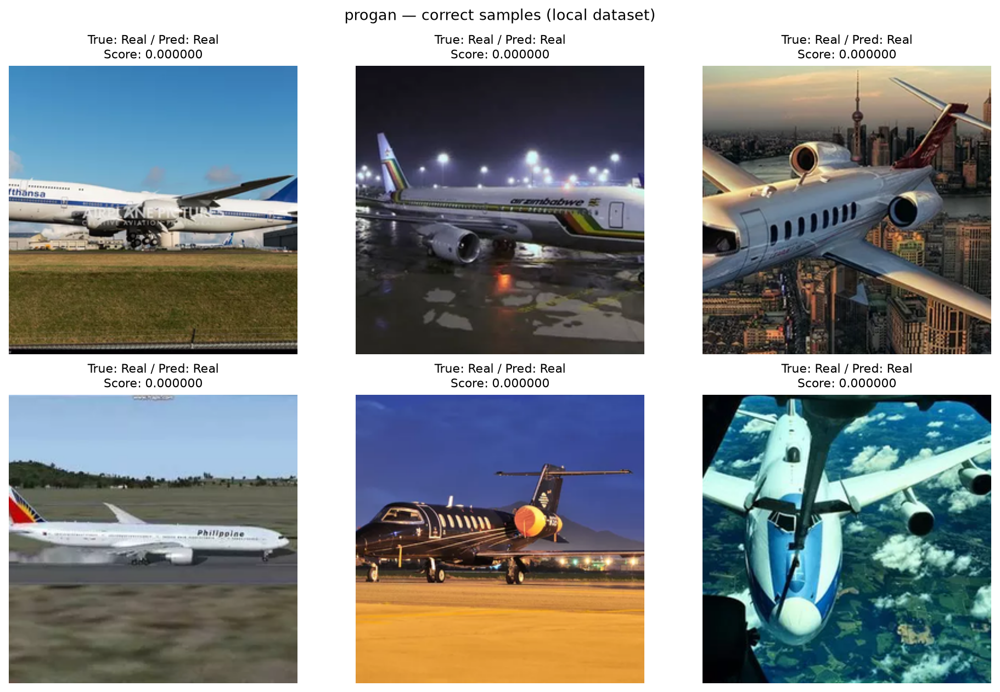

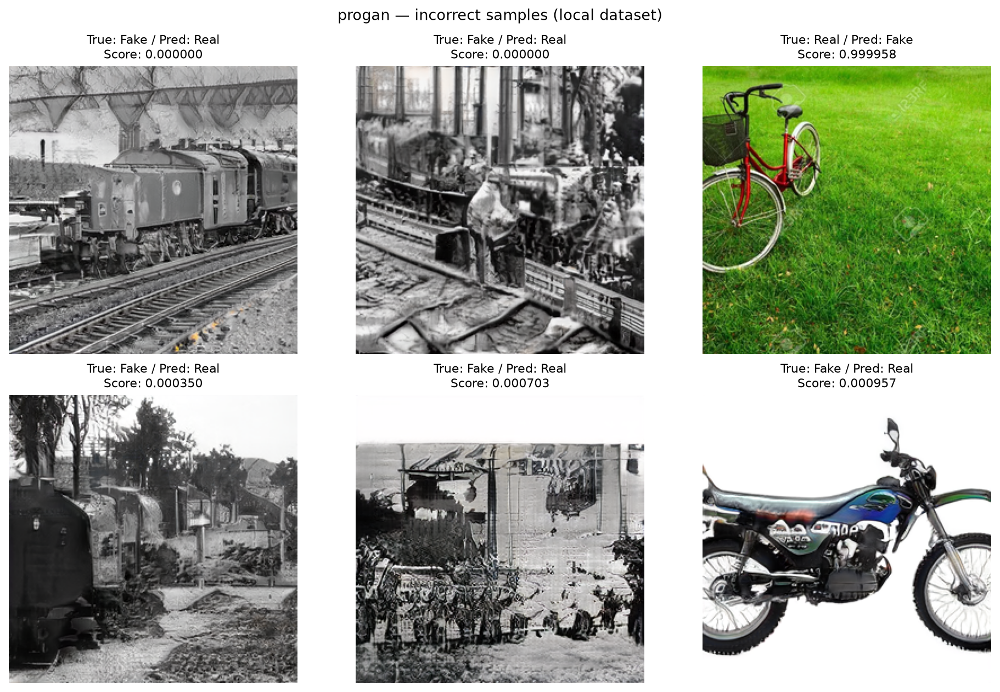

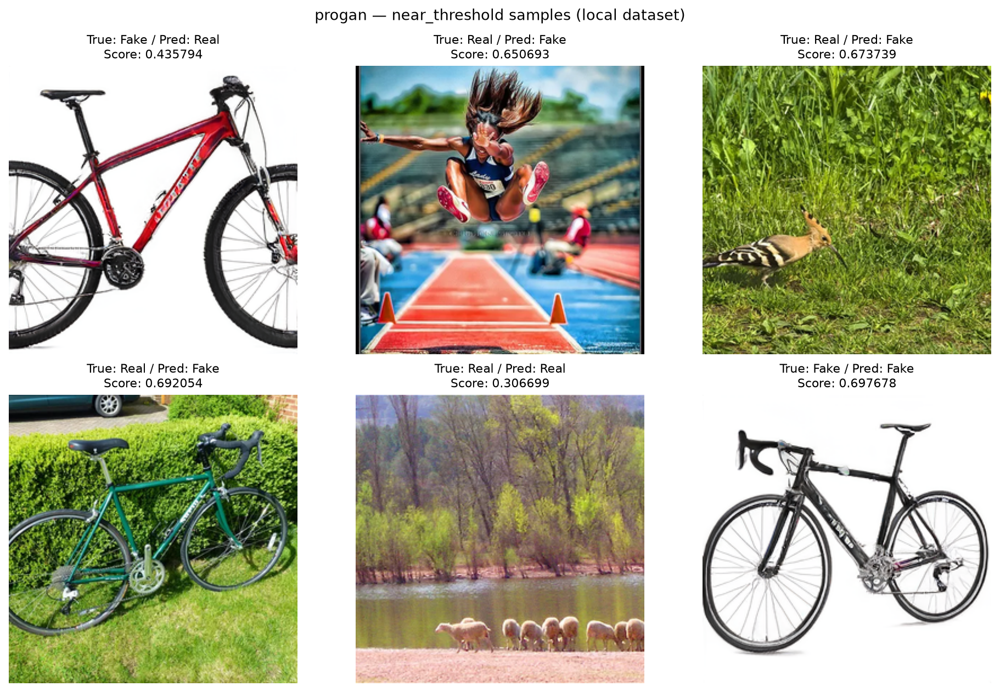

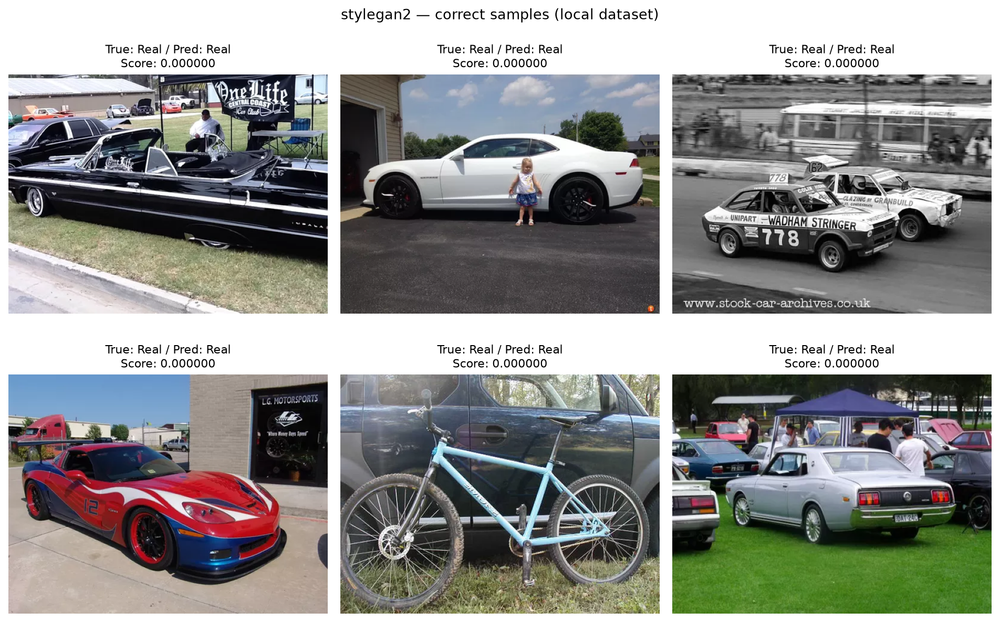

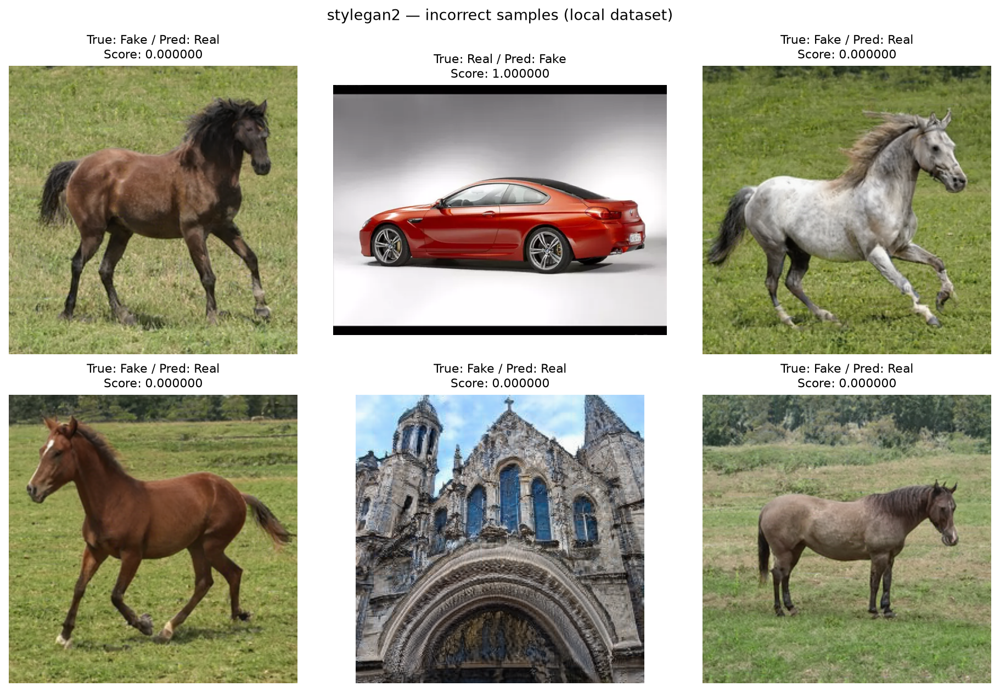

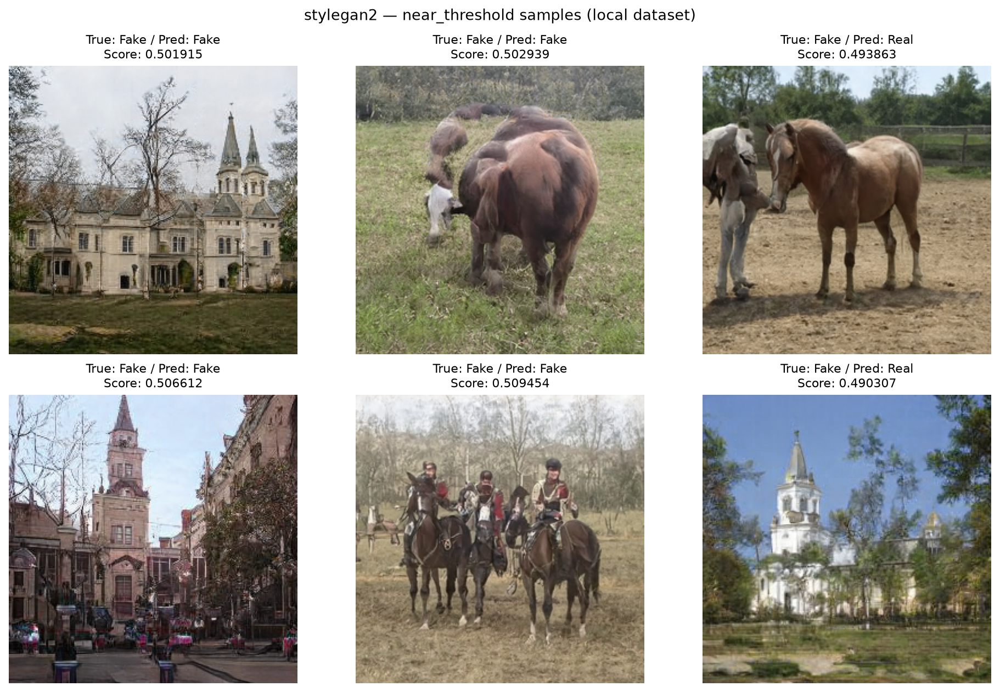

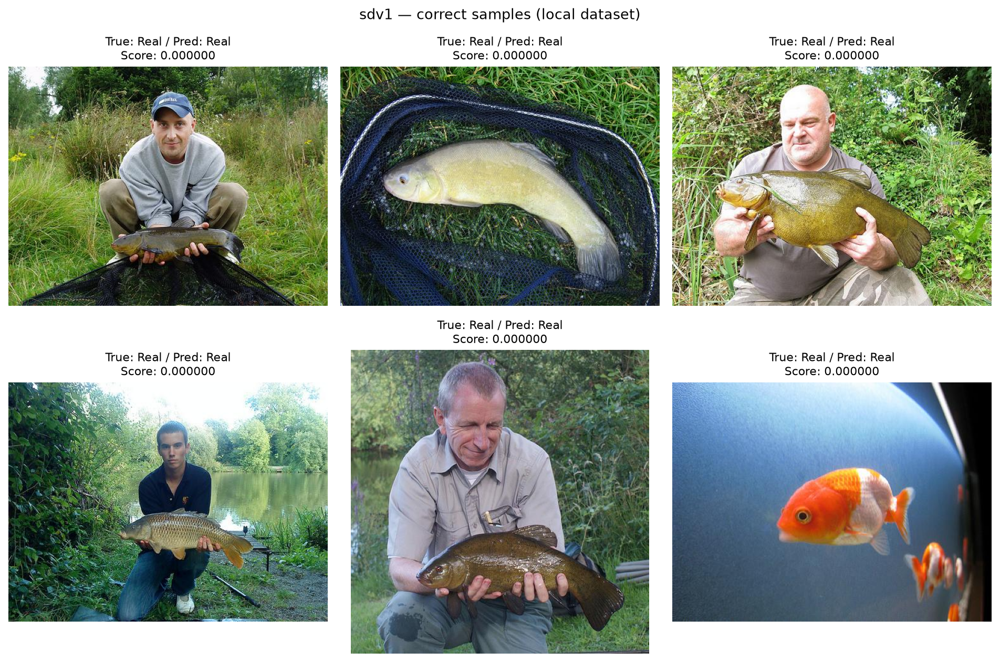

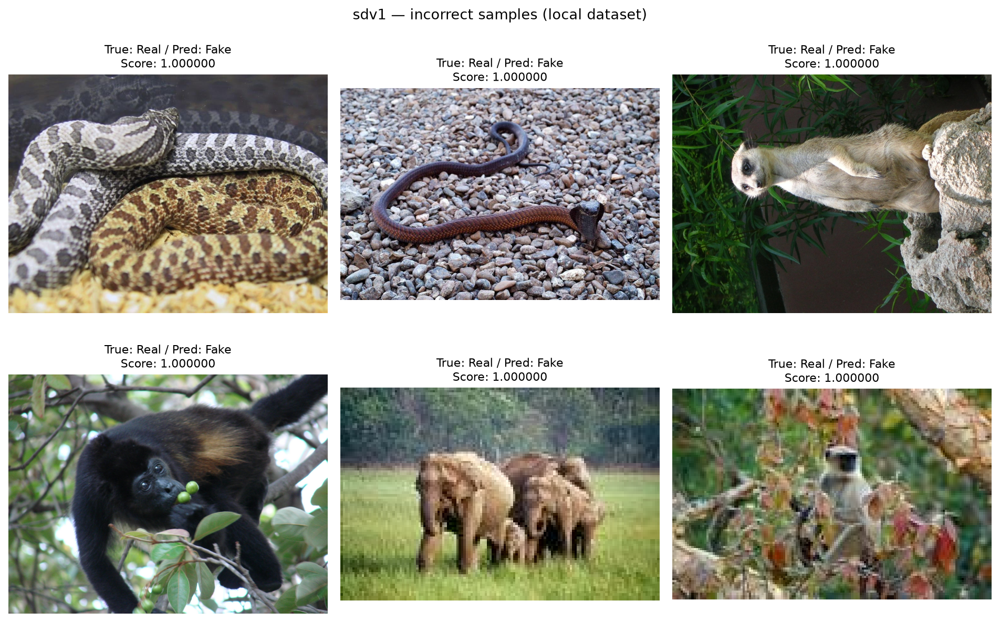

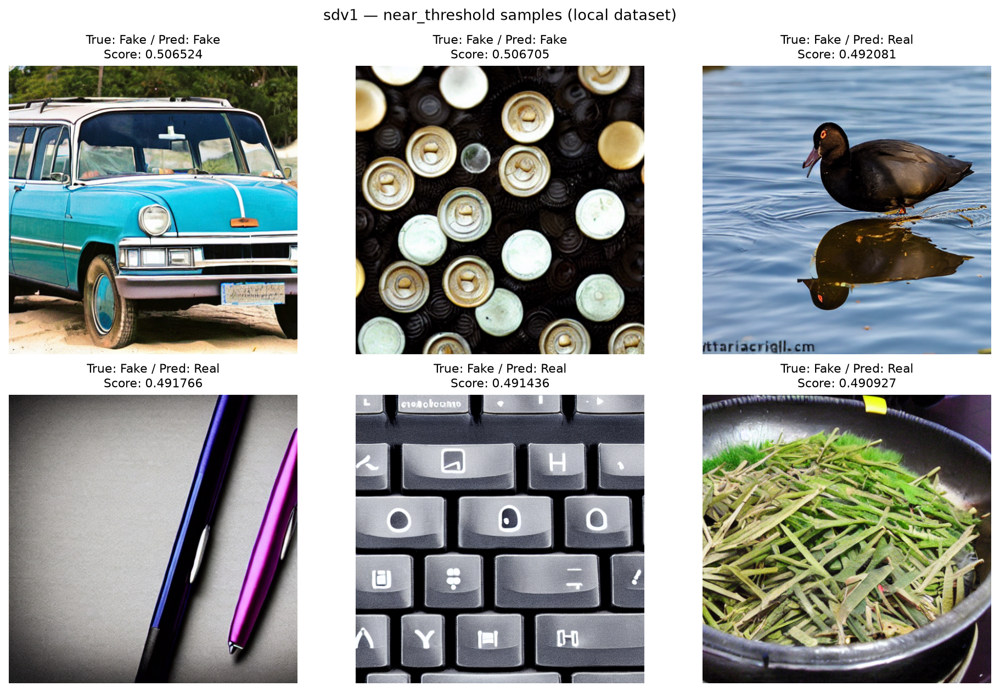

In [16]:
display(Markdown((RESULTS/'error_analysis.md').read_text(encoding='utf-8')))
for name in ['progan','stylegan2','sdv1']:
    for kind in ['correct','incorrect','near_threshold']:
        display(DisplayImage(filename=str(RESULTS/f'figures/{name}_{kind}_samples.png')))


## 17. Experiment Summary

Tổng hợp thực nghiệm local. Accuracy/Precision/Recall/F1/AP/AUC trong CSV có thang [0,1]; bảng đối chiếu paper dùng phần trăm. Thời gian tổng là tổng thời gian inference theo batch, không gồm audit/đồ thị. Toàn bộ ảnh hợp lệ phải có đúng một dòng dự đoán.

,Dataset,Real,Fake,Total,Accuracy,Precision,Recall,F1,AP,ROC_AUC,TN,FP,FN,TP,Time,MeanTime_ms,Eligible,Complete,Metric_note
0,progan,4000,4000,8000,0.997875,0.998249,0.997500,0.997874,0.999916,0.999902,3993,7,10,3990,344.315824,43.039478,8000,True,Fake=1 positive
1,stylegan2,7988,7988,15976,0.983913,0.997298,0.970456,0.983694,0.999364,0.999409,7967,21,236,7752,708.800316,44.366570,15976,True,Fake=1 positive
2,sdv1,5000,10000,15000,0.968933,0.991140,0.962000,0.976352,0.995820,0.995035,4914,86,380,9620,715.573088,47.704873,15000,True,Fake=1 positive


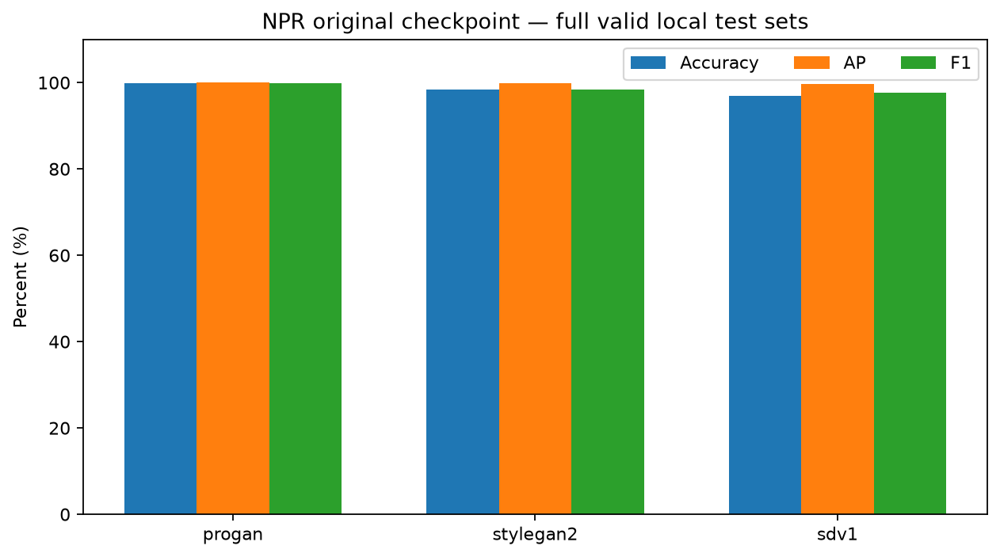

Tổng ảnh thực tế đã đánh giá: 38976
Cấu hình: D:\XLA\NPR-DeepfakeDetection\experiment_config.json


In [17]:
display(metrics)
assert not predictions.image_path.duplicated().any()
assert set(predictions.image_path)==set(manifest.loc[manifest.eligible,'image_path'])
assert metrics.Complete.all()
display(DisplayImage(filename=str(RESULTS/'figures/baseline_comparison.png')))
print('Tổng ảnh thực tế đã đánh giá:',len(predictions))
print('Cấu hình:',ROOT/'experiment_config.json')


## 18. Conclusions

Baseline gốc được giữ nguyên; kết quả phản ánh các tập local đã audit. Không kết luận tái lập đầy đủ benchmark khi provenance/split chưa được xác minh. Người 2 dùng cùng data_manifest.csv, checkpoint hash, preprocessing, threshold và metric; lưu dự đoán cải tiến vào thư mục riêng, không ghi đè baseline. Đọc README_PERSON1.md để tích hợp phần mềm.

In [18]:
display(metrics[['Dataset','Total','Accuracy','AP','F1','Complete']])
print('Inference độc lập: from inference import predict; result = predict(image_path)')
print('Bàn giao:', ROOT/'README_PERSON1.md')


,Dataset,Total,Accuracy,AP,F1,Complete
0,progan,8000,0.997875,0.999916,0.997874,True
1,stylegan2,15976,0.983913,0.999364,0.983694,True
2,sdv1,15000,0.968933,0.995820,0.976352,True


Inference độc lập: from inference import predict; result = predict(image_path)
Bàn giao: D:\XLA\NPR-DeepfakeDetection\README_PERSON1.md


## 19. Kết quả trên tập test đã làm sạch

Theo lựa chọn của người dùng, loại các ảnh có mọi pixel RGB bằng 0 khỏi phiên bản test đã làm sạch. Tiêu chí được kiểm tra trên tất cả nguồn và cả hai nhãn. Có 103 ảnh sdv1/Fake đáp ứng tiêu chí. Người dùng xác nhận đã tải một phần từ nguồn tác giả do giới hạn máy. Metrics tính lại từ dự đoán thực tế đã lưu. Time tổng hợp từ lần inference ban đầu. Người 2 dùng manifest trong results/cleaned_black103 để đánh giá các phiên bản trên cùng ảnh.

,Dataset,Real,Fake,Total,Accuracy,Precision,Recall,F1,AP,ROC_AUC,FP,FN
0,progan,4000,4000,8000,0.997875,0.998249,0.997500,0.997874,0.999916,0.999902,7,10
1,stylegan2,7988,7988,15976,0.983913,0.997298,0.970456,0.983694,0.999364,0.999409,21,236
2,sdv1,5000,9897,14897,0.975633,0.991140,0.972012,0.981482,0.996001,0.995443,86,277


,Dataset,Real_original,Fake_original,Total_original,Accuracy_original,AP_original,F1_original,FP_original,FN_original,Real_cleaned,Fake_cleaned,Total_cleaned,Accuracy_cleaned,AP_cleaned,F1_cleaned,FP_cleaned,FN_cleaned,Accuracy_delta_pp,AP_delta_pp,F1_delta_pp
0,progan,4000,4000,8000,0.997875,0.999916,0.997874,7,10,4000,4000,8000,0.997875,0.999916,0.997874,7,10,0.000000,0.000000,0.000000
1,stylegan2,7988,7988,15976,0.983913,0.999364,0.983694,21,236,7988,7988,15976,0.983913,0.999364,0.983694,21,236,0.000000,0.000000,0.000000
2,sdv1,5000,10000,15000,0.968933,0.995820,0.976352,86,380,5000,9897,14897,0.975633,0.996001,0.981482,86,277,0.669934,0.018089,0.513005


# Kết quả NPR trên tập test đã làm sạch

Người cung cấp dữ liệu xác nhận đã tải một phần dataset từ nguồn do tác giả cung cấp vì giới hạn tài nguyên máy.

Đã kiểm tra hash và extrema RGB của toàn bộ 38.976 ảnh trong snapshot test. Tiêu chí loại là mọi pixel RGB bằng 0, áp dụng cho cả hai nhãn và mọi nguồn. Có 103 đường dẫn đáp ứng tiêu chí, cùng nằm trong sdv1/Fake và có cùng SHA256. Danh sách cụ thể nằm trong excluded_images.csv.

| Dataset | Real | Fake | Total | Excluded_black |
| --- | --- | --- | --- | --- |
| progan | 4000 | 4000 | 8000 | 0 |
| stylegan2 | 7988 | 7988 | 15976 | 0 |
| sdv1 | 5000 | 9897 | 14897 | 103 |

| Dataset | Real | Fake | Total | Accuracy | Precision | Recall | F1 | AP | ROC_AUC | TN | FP | FN | TP | Time | MeanTime_ms | Eligible | Complete | Metric_note |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| progan | 4000 | 4000 | 8000 | 0.997875 | 0.9982486865148862 | 0.9975 | 0.9978742028260598 | 0.999916305279526 | 0.9999015000000001 | 3993 | 7 | 10 | 3990 | 344.3158235998271 | 43.03947794997839 | 8000 | True | Fake=1 positive |
| stylegan2 | 7988 | 7988 | 15976 | 0.9839133700550826 | 0.9972983404091085 | 0.9704556835252879 | 0.9836939280502506 | 0.9993641769193573 | 0.9994090252805348 | 7967 | 21 | 236 | 7752 | 708.800316199995 | 44.36656961692508 | 15976 | True | Fake=1 positive |
| sdv1 | 5000 | 9897 | 14897 | 0.9756326777203463 | 0.9911395013393777 | 0.9720117207234515 | 0.9814824261592613 | 0.996000526190644 | 0.9954433969889867 | 4914 | 86 | 277 | 9620 | 710.5944841688182 | 47.700509107123466 | 14897 | True | Fake=1 positive |

sdv1 đã làm sạch có 14897 ảnh, FP=86, FN=277. Accuracy/AP/F1 trong CSV dùng thang 0–1. before_after_metrics.csv ghi cả hai phiên bản và chênh lệch điểm phần trăm.

Các logit, score, nhãn dự đoán và thời gian mỗi ảnh được lấy nguyên từ lần inference baseline đã thực chạy. Metrics và biểu đồ được tính lại trên các dòng còn lại. Lần tạo phiên bản này dùng lại dự đoán đã lưu. Time/MeanTime_ms được tổng hợp từ thời gian batch phân bổ ban đầu.

Người 2 sử dụng results/cleaned_black103/data_manifest.csv cho mọi checkpoint so sánh. Giữ image_id, nhãn, preprocessing và threshold 0.5. Dùng output riêng cho mỗi lần replay hoặc mô hình cải tiến. Để chạy inference mới toàn bộ tập đã làm sạch, dùng lệnh sau từ root dự án.

```powershell
& D:\XLA\.venv\Scripts\python.exe -X utf8 evaluate_checkpoint.py --manifest results\cleaned_black103\data_manifest.csv --checkpoint NPR.pth --output results\cleaned_replay --batch-size 16 --threads 4
```

Nguồn tải từ tác giả và việc chỉ tải một phần được ghi theo thông tin người dùng cung cấp. Link/gói archive và sự tương ứng chính xác với sdv1_new vẫn cần đối chiếu. Tiêu chí làm sạch là một thay đổi protocol phải ghi khi trình bày với giảng viên.


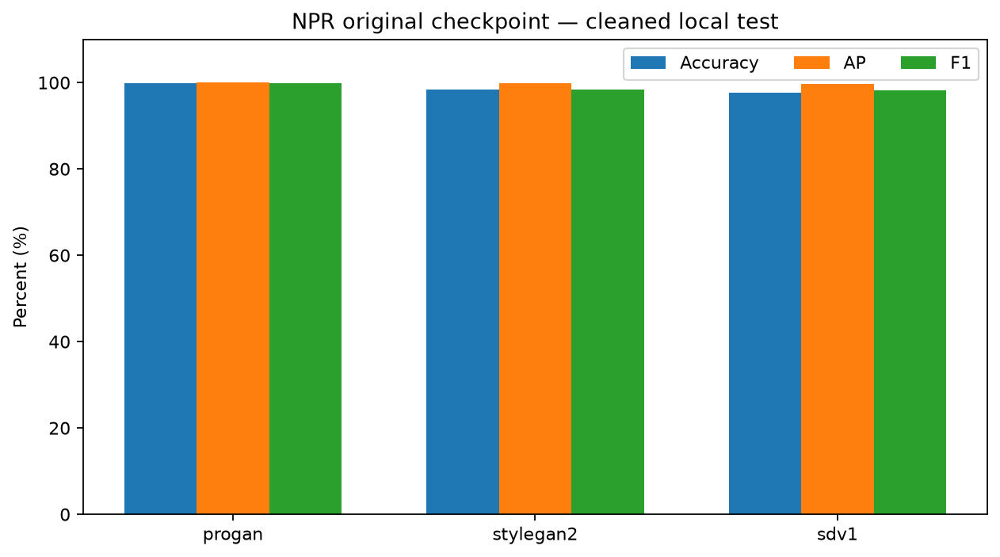

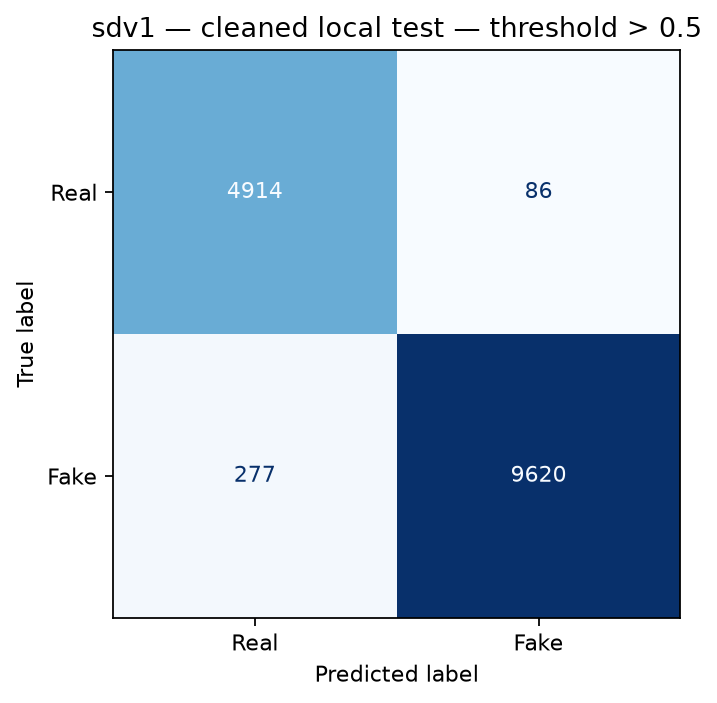

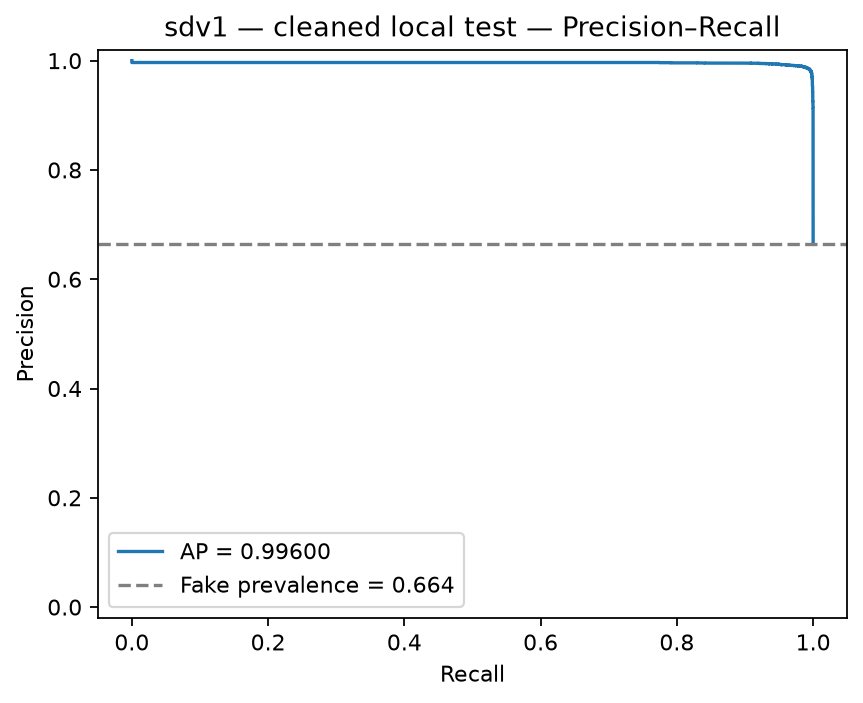

In [19]:
CLEAN_RESULTS = ROOT/'results/cleaned_black103'
clean_manifest = pd.read_csv(CLEAN_RESULTS/'data_manifest.csv')
clean_predictions = pd.read_csv(CLEAN_RESULTS/'per_image_predictions.csv')
clean_metrics = pd.read_csv(CLEAN_RESULTS/'baseline_metrics.csv')
assert len(clean_manifest) == len(clean_predictions) == 38873
assert set(clean_manifest.image_id) == set(clean_predictions.image_id)
display(clean_metrics[['Dataset','Real','Fake','Total','Accuracy','Precision','Recall','F1','AP','ROC_AUC','FP','FN']])
display(pd.read_csv(CLEAN_RESULTS/'before_after_metrics.csv'))
display(Markdown((CLEAN_RESULTS/'README.md').read_text(encoding='utf-8')))
for figure in ['baseline_comparison','sdv1_confusion_matrix','sdv1_pr_curve']:
    display(DisplayImage(filename=str(CLEAN_RESULTS/f'figures/{figure}.png')))
